# 02 · Tiền xử lý và PCA (Preprocessing + Dimensionality Reduction)

## Mục tiêu
Chuẩn hoá bộ 22 feature (feature matrix) và dùng **PCA giảm chiều xuống 2D** để trực quan hoá
không gian dữ liệu, làm nền cho phân lớp (notebook 03) và phân cụm (notebook 04).

## Yêu cầu bài tập liên quan
- Tiền xử lý + feature matrix (M04-T1), PCA (M04-T2), trực quan hoá (M04-T3).

## Phạm vi của notebook này
- **M04** — tiền xử lý, PCA, scatter tô màu theo nhãn.

## KHÔNG thuộc phạm vi
- KHÔNG đưa **nhãn `status` vào đặc trưng đầu vào của PCA** (nhãn chỉ dùng để **tô màu + diễn giải**).
- Không phân lớp (→ 03), không phân cụm (→ 04), không tổng hợp (→ 05).


## Phân công (theo `TASK_ASSIGNMENTS.md`)

| Nhiệm vụ | Phụ trách | Reviewer |
|---|---|---|
| M04-T1 Tiền xử lý + feature matrix (22 cột) | M04 | M05 |
| M04-T2 PCA (chọn số thành phần) | M04 | M06 |
| M04-T3 Trực quan hoá (scatter PC1–PC2 vs `status`) | M04 | M01 |

**Tên / MSSV thành viên:** M04 = **Trần Hoàng Thông** (MSSV `075206008044`) (xem `TEAM.md`).


## Điều kiện bắt đầu (liên kết với kết quả khám phá)

- **Đầu vào:** canonical CSV `data/processed/parkinsons_v1.csv` + **đề xuất xử lý dữ liệu**
  từ `results/quality_report.md` (M03-T3) và danh sách vấn đề (M02-T3).
- **Phụ thuộc:** M03-T2 (chất lượng) + M01-T2 (canonical CSV, qua S-T1).
- Nếu các kết quả khám phá (notebook 01) chưa bàn giao → đánh dấu **`Blocked`** trong `TASK_BOARD.md`,
  chờ M02/M03 (xem `HANDOFF.md` mục 6).


In [1]:
import sys, sklearn, pandas as pd, numpy as np
print("python", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("pandas", pd.__version__)
print("numpy", np.__version__)

python 3.14.6
scikit-learn 1.8.0
pandas 3.0.2
numpy 2.4.4


In [2]:
# M04-T1: nạp canonical CSV
import pandas as pd
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/processed/parkinsons_v1.csv").exists()), None)
assert ROOT is not None, "Thiếu canonical CSV (S-T1) -> Blocked, báo M01"

df = pd.read_csv(ROOT / "data/processed/parkinsons_v1.csv")   # đã drop 'name'; 'status' là nhãn
print(df.shape)   # (195, 23)

(195, 23)


## Bước 1 · Xác định các thuộc tính liên tục
**Mục tiêu:** xác nhận 22 feature đều là **biến liên tục (số)** — đủ để chuẩn hoá & PCA.
**Vì sao:** PCA / scaler đòi hỏi dữ liệu số; nếu có cột không số → xử lý trước.
**Làm gì:** dựa vào `df.dtypes()` (từ notebook 01), nhóm lại theo FREQ/JITTER/SHIMMER/NOISE/NONLIN
(không cần học thuộc — đối chiếu `DATA_DICTIONARY.md`).


In [3]:
# M04-T1 · Bước 1: tách danh sách feature và kiểm tra dtype số
from pandas.api.types import is_numeric_dtype

features = [c for c in df.columns if c != "status"]   # 22 cột
X = df[features]

assert len(features) == 22, f"Cần 22 feature, đang có {len(features)}"
assert all(is_numeric_dtype(t) for t in X.dtypes), "Có cột không phải số"

# nhóm feature (đối chiếu DATA_DICTIONARY.md)
groups = {
    "FREQ":    ["MDVP:Fo(Hz)", "MDVP:Fhi(Hz)", "MDVP:Flo(Hz)"],
    "JITTER":  ["MDVP:Jitter(%)", "MDVP:Jitter(Abs)", "MDVP:RAP", "MDVP:PPQ", "Jitter:DDP"],
    "SHIMMER": ["MDVP:Shimmer", "MDVP:Shimmer(dB)", "Shimmer:APQ3", "Shimmer:APQ5", "MDVP:APQ", "Shimmer:DDA"],
    "NOISE":   ["NHR", "HNR"],
    "NONLIN":  ["RPDE", "DFA", "spread1", "spread2", "D2", "PPE"],
}
assert sorted(sum(groups.values(), [])) == sorted(features), "Nhóm không khớp 22 feature"

print({g: len(c) for g, c in groups.items()})
X.dtypes.value_counts()

{'FREQ': 3, 'JITTER': 5, 'SHIMMER': 6, 'NOISE': 2, 'NONLIN': 6}


float64    22
Name: count, dtype: int64

## Bước 2 · Tách đặc trưng và nhãn
**Mục tiêu:** tách ma trận đặc trưng `X` (22 cột) và vector nhãn `y` (`status`) RÕ RÀNG.
**Vì sao:** tách sớm giúp tránh lỡ dùng nhãn làm feature (việc PCA ở đây là **không dấu (unsupervised)**).
**Câu hỏi tự kiểm:** `y` chỉ là `status`? `X` có **KHÔNG** chứa `status` hay `name`?


In [4]:
# M04-T1 · Bước 2: tách đặc trưng và nhãn
y = df["status"]
X = df[features]          # features đã loại 'status' ('name' đã bị drop từ canonical CSV)

assert "status" not in X.columns and "name" not in X.columns
assert X.shape == (195, 22)

print(X.shape, y.shape)   # (195, 22) (195,)

(195, 22) (195,)


## Bước 3 · Kiểm tra dữ liệu thiếu hoặc bất thường
**Mục tiêu:** rà lại NaN / giá trị bất thường TRƯỚC khi chuẩn hoá.
**Vì sao:** chuẩn hoá trên dữ liệu còn NaN / outlier sẽ làm lệch mean–std.
**Ghi lại:** phương án xử lý (loại dòng / imputation / giữ) — quyết định này phải ghi trong `results/`.


In [5]:
# M04-T1 · Bước 3: kiểm tra NaN / bất thường trước khi chuẩn hóa
print("NaN tổng:", int(X.isna().sum().sum()), "| dòng trùng:", int(X.duplicated().sum()))

# outlier theo quy tắc IQR (chỉ để QUAN SÁT, chưa loại dòng nào)
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
mask = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)

out = mask.sum().sort_values(ascending=False)
print("Cột có outlier:", int((out > 0).sum()), "/ 22")
print("Dòng có >=1 outlier:", int(mask.any(axis=1).sum()), "/", len(X))
out[out > 0]

NaN tổng: 0 | dòng trùng: 0
Cột có outlier: 19 / 22
Dòng có >=1 outlier: 47 / 195


NHR                 19
MDVP:PPQ            15
MDVP:RAP            14
Jitter:DDP          14
MDVP:Jitter(%)      14
Shimmer:APQ5        13
MDVP:APQ            12
MDVP:Fhi(Hz)        11
MDVP:Shimmer(dB)    10
MDVP:Flo(Hz)         9
MDVP:Shimmer         8
MDVP:Jitter(Abs)     7
Shimmer:DDA          6
Shimmer:APQ3         6
PPE                  5
spread1              4
HNR                  3
spread2              2
D2                   1
dtype: int64

## Bước 4 · Đề xuất và ghi lại phương án xử lý dữ liệu
**Mục tiêu:** **trình bày** (chưa chạy) phương án chuẩn hoá + xử lý đã chọn, kèm **lý do**.
**Quy ước (xem `docs/REPRODUCIBILITY.md`):** scaler mặc định `StandardScaler` nếu không có lý do khác.
**Làm gì:** viết 2–3 dòng giải trình: chọn chuẩn hoá nào, có impute không, vì sao.

**Giải thích:**
- **Thiếu / trùng:** không có NaN, không có dòng trùng → không impute, không loại dòng.
- **Outlier:** theo IQR có 19/22 cột và 47/195 dòng bị đánh dấu. Giữ nguyên toàn bộ dòng vì loại sẽ mất ~24% dữ liệu trên tập chỉ có 195 mẫu, và các cột jitter/shimmer vốn lệch phải nên chưa chắc là dữ liệu sai.
- **Chuẩn hóa:** `StandardScaler`, fit chỉ trên 22 feature (không dùng `status`). Lý do: các feature chênh thang đo lớn (vd `MDVP:Jitter(Abs)` cỡ 1e-5 so với `MDVP:Fo(Hz)` cỡ 100), PCA nhạy với thang đo. Theo quy ước nhóm (`REPRODUCIBILITY.md` §3).
- **Seed:** 42.

## Bước 5 · Chuẩn hoá dữ liệu (khi phù hợp)
**Mục tiêu:** chuẩn hoá `X` để các feature cùng thang (đặc biệt khi chênh scale, vd `MDVP:Jitter(Abs)`).
**Vì sao:** PCA nhạy với thang đo; chuẩn hoá giúp phương sai phản ánh đúng cấu trúc.
**Lưu ý:** scaler **fit trên feature (không dùng nhãn)**; ghi seed nếu có.


In [6]:
# M04-T1 · Bước 5: chuẩn hóa (StandardScaler, fit chỉ trên feature, không dùng 'status')
import numpy as np
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xs = scaler.fit_transform(X)                          # ndarray (195, 22), dùng cho PCA
Xs_df = pd.DataFrame(Xs, columns=features, index=X.index)   # bản có tên cột, để M05/M06 đọc

assert Xs.shape == (195, 22)
assert not np.isnan(Xs).any()
assert np.allclose(Xs.mean(axis=0), 0, atol=1e-9)    # mean ~ 0
assert np.allclose(Xs.std(axis=0), 1, atol=1e-9)     # std ~ 1

print(Xs.shape)   # (195, 22)

(195, 22)


## Bước 6 · Thực hiện PCA giảm chiều xuống 2D
**Mục tiêu:** chiếu `Xs` xuống 2 thành phần chính (để vẽ), và **ghi nhận tổng phương sai được giải thích**.
**Quy ước (xem `docs/REPRODUCIBILITY.md`):** nếu cần nhiều hơn 2 thành phần cho ngưỡng variance,
nêu rõ; ở đây giảm về **2D** để trực quan.
**Lưu ý:** PCA là **unsupervised** — không dùng `y` trong quá trình.


In [7]:
# M04-T2 · Bước 6: PCA về 2D (unsupervised, không dùng y)
from sklearn.decomposition import PCA

SEED = 42
pca = PCA(n_components=2, random_state=SEED)
X2 = pca.fit_transform(Xs)                 # (195, 2) để vẽ ở Bước 7
evr = pca.explained_variance_ratio_

print(X2.shape)                            # (195, 2)
print("PC1:", round(evr[0], 4), "| PC2:", round(evr[1], 4), "| tổng:", round(evr.sum(), 4))

# ngưỡng variance (quy ước nhóm: >= 90%) -> cần bao nhiêu thành phần?
pca_full = PCA(random_state=SEED).fit(Xs)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90) + 1)
print("Số thành phần để đạt >= 90%:", n90, "| Phương sai tích lũy:", round(cum[n90 - 1], 4))

(195, 2)
PC1: 0.589 | PC2: 0.113 | tổng: 0.702
Số thành phần để đạt >= 90%: 6 | Phương sai tích lũy: 0.9161


## Bước 7 · Vẽ scatter plot, tô màu theo nhãn
**Mục tiêu:** scatter **PC1 vs PC2**, tô màu theo `status` (0/1) để **quan sát** mức phân tách.
**Luật:** `status` chỉ để **tô màu + đọc hình** — **KHÔNG** là input của PCA.
**Câu hỏi tự kiểm:** trên hình, hai nhóm có tách rõ hay chồng lấp? Có cụm nhỏ riêng không?


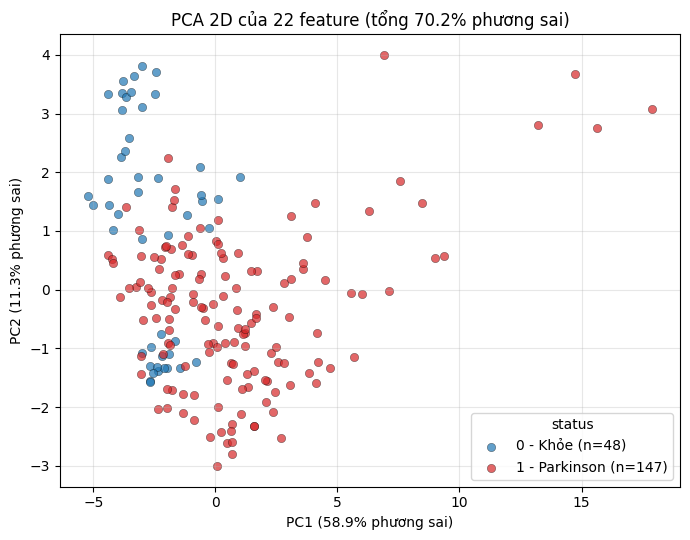

In [8]:
# M04-T3 · Bước 7: scatter PC1-PC2, tô màu theo 'status' (chỉ để tô màu, KHÔNG là input của PCA)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5.5))
for label, name, color in [(0, "0 - Khỏe", "tab:blue"), (1, "1 - Parkinson", "tab:red")]:
    m = (y == label).to_numpy()
    ax.scatter(X2[m, 0], X2[m, 1], c=color, label=f"{name} (n={m.sum()})",
               alpha=0.7, edgecolor="k", linewidth=0.3)

ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}% phương sai)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}% phương sai)")
ax.set_title(f"PCA 2D của 22 feature (tổng {evr.sum()*100:.1f}% phương sai)")
ax.legend(title="status")
ax.grid(alpha=0.3)
fig.tight_layout()

FIG_DIR = ROOT / "results/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "02_pca_scatter.png", dpi=150)
plt.show()

## Bước 8 · Histogram phân bố các feature 

**Mục tiêu:** xem hình dạng phân bố của từng feature trong 22 feature, và so sánh nhóm khỏe với nhóm Parkinson.

**Vì sao:** phân bố lệch hay có đuôi dài ảnh hưởng đến cách đọc outlier ở Bước 3 và đến việc chuẩn hóa/PCA.

**Làm gì:** vẽ 22 histogram, tô theo `status` (nhãn chỉ dùng để tô màu, không là input). Dùng `density=True` vì hai nhóm chênh số mẫu (n=48 và n=147), nên cột cao thấp không so trực tiếp theo số đếm.

**Đầu ra:** `results/figures/m04-t3_histograms.png`.

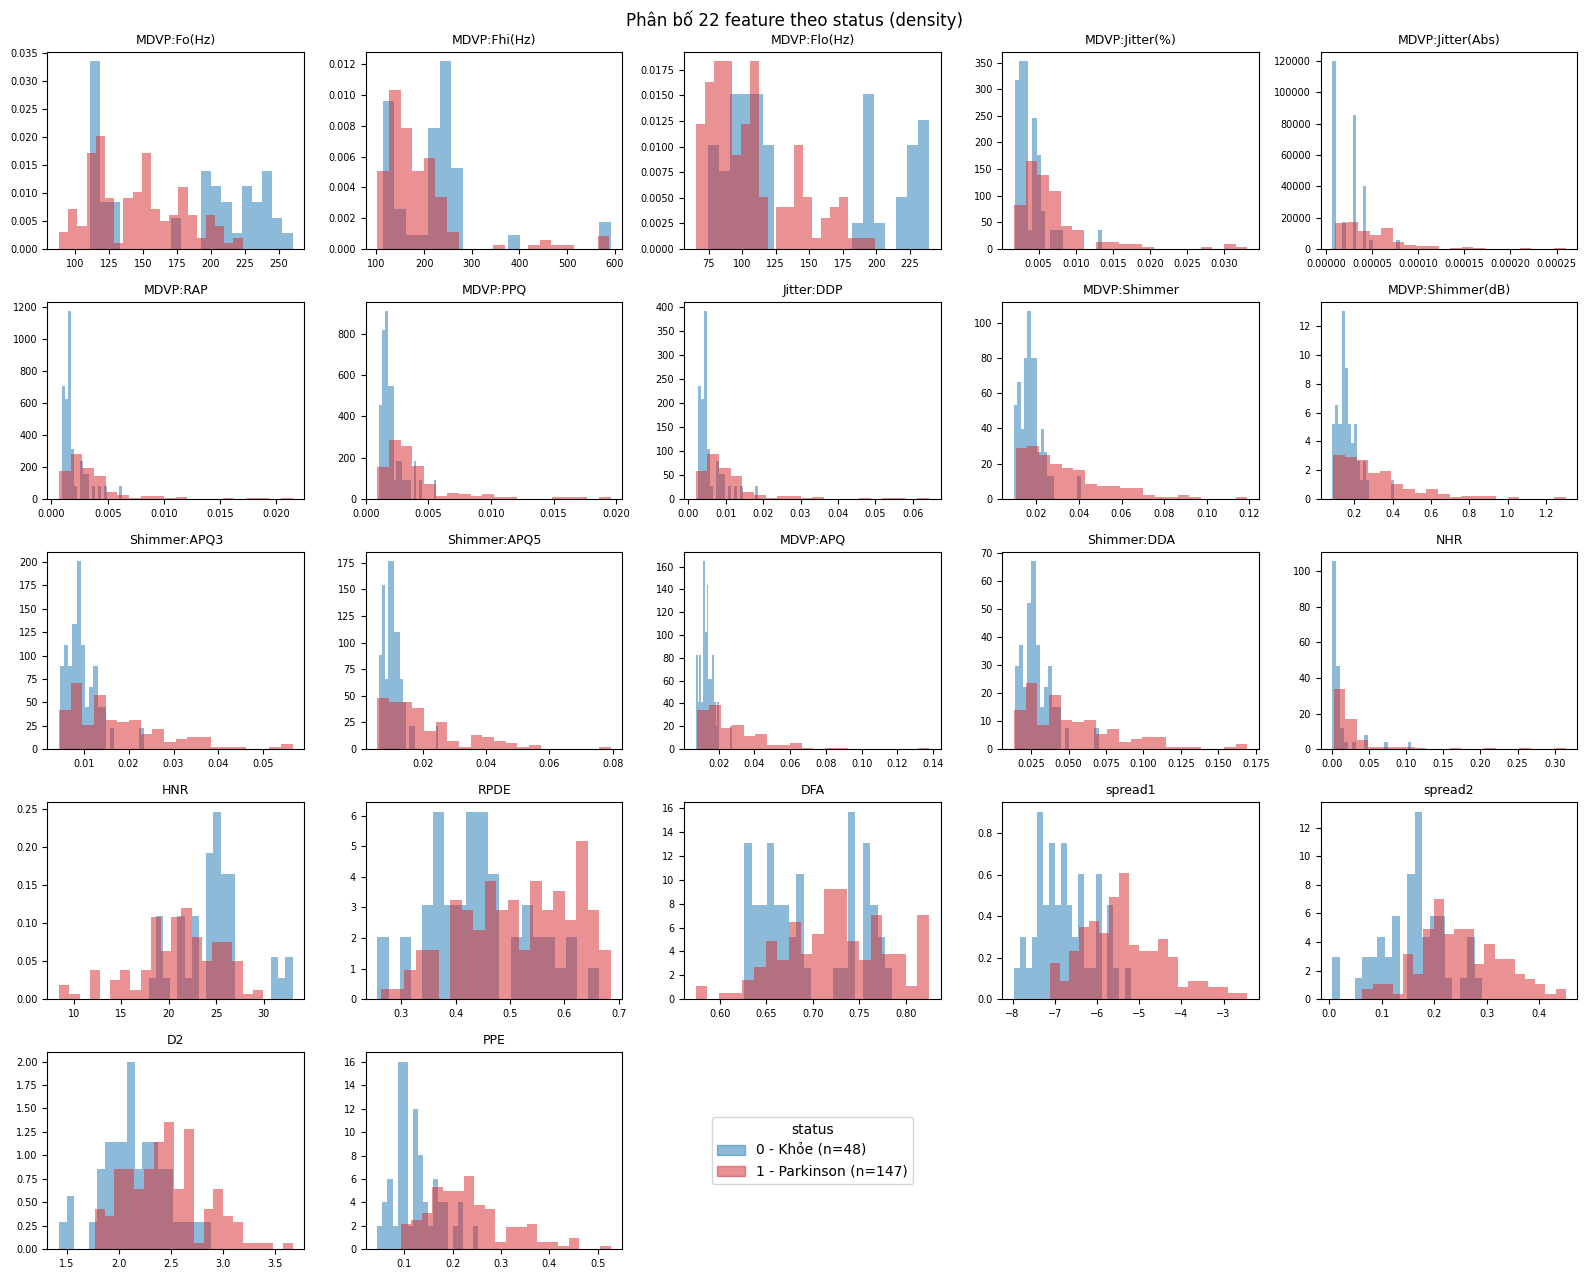

In [9]:
# M04-T3: Bước 8 : histogram phân bố 22 feature, tô theo status (density vì n=48 vs 147)
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = ROOT / "results/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

ncols = 5
nrows = int(np.ceil(len(features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.6 * nrows))
flat = axes.ravel()
for ax, f in zip(flat, features):
    for label, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(X.loc[y == label, f], bins=20, density=True, alpha=0.5, color=color)
    ax.set_title(f, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in flat[len(features):]:
    ax.axis("off")

handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in ("tab:blue", "tab:red")]
flat[len(features)].legend(handles, ["0 - Khỏe (n=48)", "1 - Parkinson (n=147)"],
                           title="status", loc="center")
fig.suptitle("Phân bố 22 feature theo status (density)")
fig.tight_layout()
fig.savefig(FIG_DIR / "m04-t3_histograms.png", dpi=130)
plt.show()

## Bước 9 · Heatmap tương quan giữa các feature 

**Mục tiêu:** tìm các feature có tương quan mạnh với nhau (thông tin trùng lặp).

**Vì sao:** các feature tương quan cao làm một vài thành phần PCA gom nhiều phương sai, và cần báo cho M05 (phân lớp), M06 (phân cụm).

**Làm gì:** tính tương quan Pearson trên 22 feature gốc (chưa chuẩn hóa, vì hệ số tương quan không đổi khi đổi thang đo), vẽ heatmap thang −1 đến 1.

**Đầu ra:** `results/figures/m04-t3_corr_heatmap.png`.

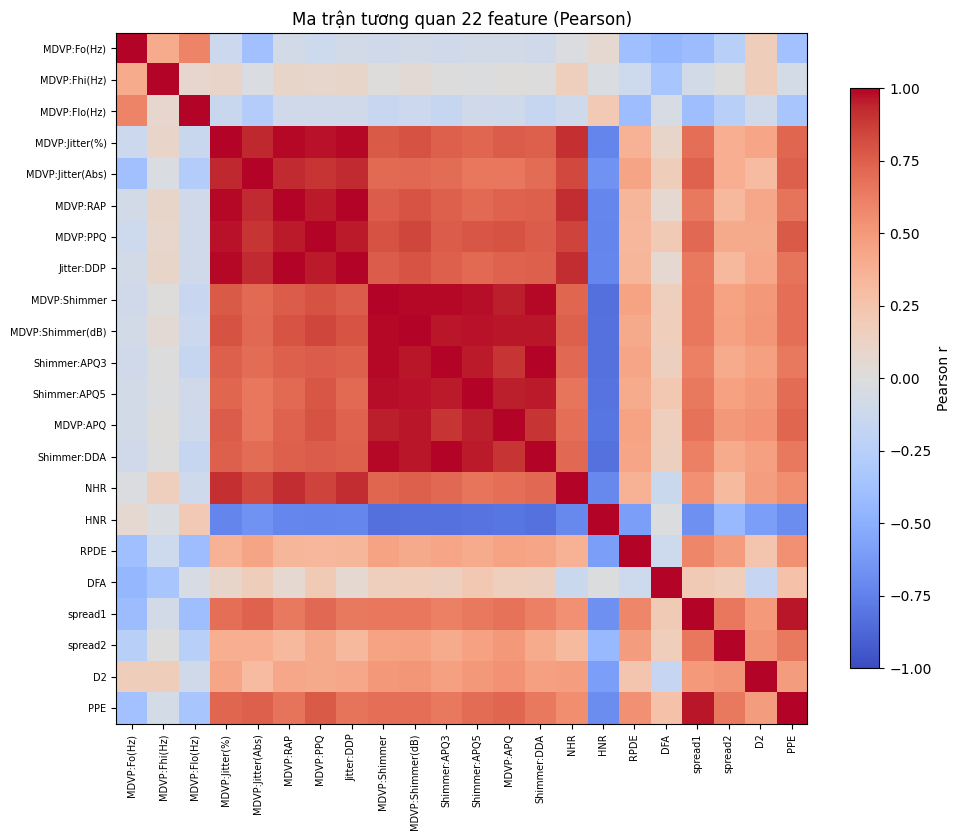

cặp |r| >= 0.9: 26 / 231
cặp |r| >= 0.7: 79
feature lệch (|skew| > 1): 14 / 22


In [10]:
# M04-T3: heatmap tương quan Pearson giữa 22 feature
corr = X.corr()

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))
ax.set_xticklabels(features, rotation=90, fontsize=7)
ax.set_yticklabels(features, fontsize=7)
fig.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
ax.set_title("Ma trận tương quan 22 feature (Pearson)")
fig.tight_layout()
fig.savefig(FIG_DIR / "m04-t3_corr_heatmap.png", dpi=130)
plt.show()

# số liệu để ghi nhận xét
iu = np.triu_indices(len(features), k=1)
r = corr.values[iu]
print("cặp |r| >= 0.9:", int((np.abs(r) >= 0.9).sum()), "/", len(r))
print("cặp |r| >= 0.7:", int((np.abs(r) >= 0.7).sum()))
print("feature lệch (|skew| > 1):", int((X.skew().abs() > 1).sum()), "/ 22")

## Kết quả & nhận xét (sinh viên tự điền — KHÔNG điền sẵn)

**Bảng ghi nhận (điền KHI CHẠY THẬT):**

| Hạng mục | Giá trị | Ghi chú |
|---|---|---|
| Scaler đã dùng | StandardScaler | Fit chỉ trên 22 feature, không dùng `status`. Các feature chênh thang đo lớn (vd `MDVP:Jitter(Abs)` so với `MDVP:Fo(Hz)`), PCA nhạy với thang đo. Seed = 42 |
| Xử lý NaN / outlier | Giữ nguyên 195 dòng | Không có NaN, không có dòng trùng. Theo IQR: 19/22 cột và 47/195 dòng có outlier, nhiều nhất ở `NHR` (19), `MDVP:PPQ` (15), `MDVP:RAP`, `Jitter:DDP`, `MDVP:Jitter(%)` (14 mỗi cột). Chỉ quan sát, không loại dòng |
| Số thành phần giữ (PCA) | 2 (để vẽ) | Cần 6 thành phần để đạt ngưỡng ≥ 90% (tích lũy 91.61%) |
| Phương sai PC1 giải thích | 58.9% | |
| Phương sai PC2 giải thích | 11.3% | |
| Tổng phương sai PC1+PC2 | 70.2% | Bỏ đi khoảng 29.8% |
| Hình phân tách 2 nhóm? | Tách một phần, chồng lấp đáng kể | Xem nhận xét bên dưới |

**Nhận xét từ hình scatter:**
- Nhóm 0 (khỏe, n=48) tập trung ở bên trái (PC1 âm). Có một cụm khá riêng ở góc trên bên trái (PC1 khoảng −5 đến −2, PC2 trên 1.5) gần như chỉ có nhóm 0.
- Một phần nhóm 0 nằm ở phía dưới bên trái, lẫn với các điểm nhóm 1 → vùng chồng lấp.
- Nhóm 1 (Parkinson, n=147) trải rộng hơn nhiều trên PC1, và có 4 điểm nằm xa về phía PC1 dương (PC1 > 13).



**Câu hỏi gợi ý (đặt dựa trên kết quả THẬT):**
1. Tổng phương sai PC1+PC2 giải thích được bao nhiêu? Còn bao nhiêu thông tin bị bỏ đi?
-> **PC1+PC2 giải thích 70.2% phương sai, nên khoảng 29.8% thông tin bị bỏ khi vẽ 2D.**
2. Hai nhóm (0/1) có tách rõ trên trục PC1/PC2 không? Nếu không, điều đó nói gì về độ khó phân lớp?
-> **Hai nhóm tách một phần nhưng chồng lấp ở vùng bên trái-dưới. PCA không dùng nhãn nên không tối ưu cho việc tách lớp, và hình chỉ giữ 70% phương sai. Vì vậy chồng lấp trên hình chưa đủ để kết luận bài phân lớp khó hay dễ, việc đó để M05 kiểm chứng bằng CV.**
3. Có cần thêm thành phần PCA (nhiều hơn 2) để nắm đủ phương sai không?
-> **Cần thêm: 2 thành phần chỉ phù hợp để quan sát. Muốn giữ ≥ 90% phương sai thì cần 6 thành phần.**



## Nhận xét Bước 8–9

**Histogram (phân bố theo `status`):**
- 14/22 feature lệch phải (|skew| > 1), nhiều nhất là `NHR` (skew khoảng 4.2). Điều này khớp với việc IQR đánh dấu nhiều outlier ở Bước 3: phần lớn là đuôi dài tự nhiên của phân bố, không nhất thiết là dữ liệu sai.
- Nhóm Parkinson lệch về phía "tệ hơn" ở nhiều feature (so sánh trung vị, nhóm khỏe → nhóm Parkinson):
  - Tần số cơ bản thấp hơn: `MDVP:Fo(Hz)` 199 → 145.2 Hz, `MDVP:Flo(Hz)` 113.9 → 99.77 Hz.
  - Jitter/shimmer cao hơn: `MDVP:Jitter(%)` 0.00336 → 0.00544, `MDVP:Shimmer` 0.0167 → 0.0284.
  - `HNR` thấp hơn: 25 → 21.4.
  - `spread1` −6.83 → −5.44, `spread2` 0.167 → 0.241, `PPE` 0.115 → 0.223.
- Nhưng hai nhóm chồng lấp ở hầu hết feature (n=48 và n=147, mỗi histogram 20 bin nên hình khá nhiễu). Histogram chỉ cho thấy xu hướng lệch, chưa đủ để kết luận feature nào phân lớp tốt.

**Heatmap tương quan:**
- 26/231 cặp feature có |r| ≥ 0.9, và 79 cặp có |r| ≥ 0.7.
- Trong nhóm jitter, mọi cặp có r ≥ 0.9; trong nhóm shimmer cũng vậy. `NHR` tương quan dương với các feature jitter (r từ 0.83 đến 0.92). `HNR` tương quan âm với jitter/shimmer (r từ −0.84 đến −0.66).
- Trong nhóm NONLIN, `spread1` và `PPE` tương quan r = 0.96.
- `Jitter:DDP` bằng đúng 3 lần `MDVP:RAP`, và `Shimmer:DDA` bằng đúng 3 lần `Shimmer:APQ3` (tỉ lệ trung vị là 3.0), nên hai cặp này có r = 1.0 và trùng thông tin hoàn toàn. Giữ nguyên các cột vì canonical CSV không được sửa; ghi nhận để M03/M05 cân nhắc.


## Checklist

### Hoàn thành nhiệm vụ
- [x] Đã tách `X` (feature) và `y` (label), xác nhận `X` **không** chứa `status`/`name`.
- [x] Đã kiểm tra NaN/outlier + **ghi phương án xử lý** (không chạy đại).
- [x] Đã chuẩn hoá (nếu chọn) và **ghi rõ scaler + lý do**.
- [x] Đã chạy PCA về 2 thành phần + ghi **tỷ lệ phương sai**.
- [x] Đã vẽ scatter PC1–PC2 **tô màu theo `status`** (label không làm feature).

### Kiểm tra chất lượng
- [x] Số liệu (variance, ratio) là **thực** (không bịa), đã lưu figure vào `results/figures/`.
- [x] Đầu vào chỉ nạp từ canonical CSV `data/processed/parkinsons_v1.csv`, không tạo bản CSV riêng.
- [ ] Quyết định tiền xử lý được ghi trong `results/` + `docs/REPRODUCIBILITY.md`.

### Bàn giao
- [ ] Đã chuyển M04-T1..T3 sang `Review` trong `TASK_BOARD.md`.
- [ ] Đã thông báo reviewer (M05 cho feature matrix, M06 cho PCA, M01-gate cho TVH).

### Vấn đề chưa giải quyết
- [ ] M03-T2 (`results/quality_report.md`) chưa bàn giao. M04-T1 đã chạy trước theo canonical CSV và bàn giao của M02-T3 (`results/m02_exploration.md`: cần chuẩn hóa, không xóa outlier tự động). Cần đối chiếu lại khi M03 có đề xuất xử lý.
- [ ] `Xs` được fit trên toàn bộ 195 dòng: dùng được cho PCA/phân cụm. M05 phải dùng `make_scaler()` (`src/preprocessing.py`) trong Pipeline khi CV để tránh data leakage.

## Tái lập & xử lý Blocked

- **Nguồn dữ liệu:** canonical CSV `data/processed/parkinsons_v1.csv` + `results/quality_report.md` (M03-T3).
- **Đầu vào:** feature matrix (22 cột) chuẩn hoá. **Đầu ra:** PCA 2D + figure + tỷ lệ phương sai.
- **Ghi lại** (vào `results/` + `docs/REPRODUCIBILITY.md`): scaler, ngưỡng variance, seed, phiên bản thư viện.
- **Không hardcode** đường dẫn cá nhân; chạy từ gốc project (Colab xem `docs/COLAB_GUIDE.md`).
- **Blocked:** thiếu chất lượng (M03-T2) hoặc canonical CSV (S-T1) → đánh dấu trong `TASK_BOARD.md`,
  ghi rõ thiếu gì, ai cung cấp; thông báo M01. Xem `HANDOFF.md` mục 6.
